# Loan Default Analysis: Data Cleaning & EDA

Cleaning a LendingClub-style loan dataset (27,003 rows × 47 columns) and exploring which factors relate to loan default.

**Data file expected:** `loan_train.csv` (not included in this repo, see `data/README.md`).

**Notebook flow:** inspect → drop leakage/ID columns → convert text to numbers → handle missing values → outliers → default-rate EDA → summary of insights.


In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df =pd.read_csv("loan_train.csv")

In [3]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


In [4]:
df.columns


Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
       'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record',
       'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'last_credit_pull_d', 'pub_rec_bankruptcies'],
      dtype='str')

In [5]:
df.shape


(27003, 47)

In [6]:
df.dtypes

id                           int64
member_id                    int64
loan_amnt                    int64
funded_amnt                  int64
funded_amnt_inv            float64
term                           str
int_rate                       str
installment                float64
grade                          str
sub_grade                      str
emp_title                      str
emp_length                     str
home_ownership                 str
annual_inc                 float64
verification_status            str
issue_d                        str
loan_status                  int64
url                            str
desc                           str
purpose                        str
title                          str
zip_code                       str
addr_state                     str
dti                        float64
delinq_2yrs                  int64
earliest_cr_line               str
inq_last_6mths               int64
mths_since_last_delinq     float64
mths_since_last_reco

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27003 entries, 0 to 27002
Data columns (total 47 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       27003 non-null  int64  
 1   member_id                27003 non-null  int64  
 2   loan_amnt                27003 non-null  int64  
 3   funded_amnt              27003 non-null  int64  
 4   funded_amnt_inv          27003 non-null  float64
 5   term                     27003 non-null  str    
 6   int_rate                 27003 non-null  str    
 7   installment              27003 non-null  float64
 8   grade                    27003 non-null  str    
 9   sub_grade                27003 non-null  str    
 10  emp_title                25321 non-null  str    
 11  emp_length               26273 non-null  str    
 12  home_ownership           27003 non-null  str    
 13  annual_inc               27003 non-null  float64
 14  verification_status      27003 no

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,27003.0,676300.725660,209044.025722,54734.00,512663.000000,657052.0000,8.271015e+05,1.077430e+06
member_id,27003.0,842247.267341,264254.127295,70699.00,661775.500000,840072.0000,1.035238e+06,1.314167e+06
loan_amnt,27003.0,11087.946710,7392.758683,500.00,5300.000000,9750.0000,1.500000e+04,3.500000e+04
funded_amnt,27003.0,10816.216717,7131.666342,500.00,5175.000000,9600.0000,1.500000e+04,3.500000e+04
funded_amnt_inv,27003.0,10251.064645,7066.203699,0.00,5000.000000,8731.0261,1.402500e+04,3.500000e+04
installment,27003.0,323.375002,209.866524,15.69,165.805000,277.5700,4.270000e+02,1.302690e+03
annual_inc,27003.0,68777.705736,67648.525419,4000.00,40000.000000,59000.0000,8.200000e+04,6.000000e+06
loan_status,27003.0,0.147280,0.354391,0.00,0.000000,0.0000,0.000000e+00,1.000000e+00
dti,27003.0,13.259037,6.662728,0.00,8.130000,13.3500,1.852000e+01,2.999000e+01
delinq_2yrs,27003.0,0.149169,0.499802,0.00,0.000000,0.0000,0.000000e+00,1.100000e+01


In [9]:
#missing values
missing_report = pd.DataFrame({
    "Missing_Count":
        df.isna().sum(),

    "Missing_Percentage":
        df.isna().mean() * 100
})
missing_report

,Missing_Count,Missing_Percentage
id,0,0.000000
member_id,0,0.000000
loan_amnt,0,0.000000
funded_amnt,0,0.000000
funded_amnt_inv,0,0.000000
term,0,0.000000
int_rate,0,0.000000
installment,0,0.000000
grade,0,0.000000
sub_grade,0,0.000000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
print(df["id"].duplicated().sum())
print (df["member_id"].duplicated().sum())

0
0


In [12]:
cd=df.copy()

In [13]:
cols_to_drop = [

    "id", "member_id", "url", "zip_code", "grade",
    "funded_amnt", "funded_amnt_inv",
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "last_credit_pull_d",
    "desc","emp_title"
]

cd= cd.drop(columns=cols_to_drop)

print(cd.shape)   

(27003, 26)


In [14]:
cd.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'sub_grade',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'purpose', 'title', 'addr_state', 'dti',
       'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'pub_rec_bankruptcies'],
      dtype='str')

In [15]:
cd.info()

<class 'pandas.DataFrame'>
RangeIndex: 27003 entries, 0 to 27002
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   loan_amnt               27003 non-null  int64  
 1   term                    27003 non-null  str    
 2   int_rate                27003 non-null  str    
 3   installment             27003 non-null  float64
 4   sub_grade               27003 non-null  str    
 5   emp_length              26273 non-null  str    
 6   home_ownership          27003 non-null  str    
 7   annual_inc              27003 non-null  float64
 8   verification_status     27003 non-null  str    
 9   issue_d                 27003 non-null  str    
 10  loan_status             27003 non-null  int64  
 11  purpose                 27003 non-null  str    
 12  title                   26994 non-null  str    
 13  addr_state              27003 non-null  str    
 14  dti                     27003 non-null  float64
 

In [16]:
cd.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amnt,27003.0,11087.946710,7392.758683,500.00,5300.000,9750.00,15000.00,35000.00
installment,27003.0,323.375002,209.866524,15.69,165.805,277.57,427.00,1302.69
annual_inc,27003.0,68777.705736,67648.525419,4000.00,40000.000,59000.00,82000.00,6000000.00
loan_status,27003.0,0.147280,0.354391,0.00,0.000,0.00,0.00,1.00
dti,27003.0,13.259037,6.662728,0.00,8.130,13.35,18.52,29.99
delinq_2yrs,27003.0,0.149169,0.499802,0.00,0.000,0.00,0.00,11.00
inq_last_6mths,27003.0,0.871088,1.072138,0.00,0.000,1.00,1.00,8.00
mths_since_last_delinq,9608.0,35.700354,22.069853,0.00,18.000,34.00,52.00,120.00
mths_since_last_record,1938.0,68.994324,44.262656,0.00,8.000,90.00,104.00,129.00
open_acc,27003.0,9.269452,4.391485,2.00,6.000,9.00,12.00,44.00


In [17]:
#missing values
missing_report = pd.DataFrame({
    "Missing_Count":
        cd.isna().sum(),

    "Missing_Percentage":
        cd.isna().mean() * 100
})
missing_report

,Missing_Count,Missing_Percentage
loan_amnt,0,0.000000
term,0,0.000000
int_rate,0,0.000000
installment,0,0.000000
sub_grade,0,0.000000
emp_length,730,2.703403
home_ownership,0,0.000000
annual_inc,0,0.000000
verification_status,0,0.000000
issue_d,0,0.000000


In [18]:
cd["has_delinq"] = cd["mths_since_last_delinq"].apply(lambda x: 0 if pd.isna(x) else 1)
cd["has_record"] = cd["mths_since_last_record"].apply(lambda x: 0 if pd.isna(x) else 1)

Create flag columns for `mths_since_last_record` and `mths_since_last_delinq`

عشان اقدر احلل منغير ما اغير فى القيم

In [19]:
print(cd["has_delinq"].value_counts(normalize=True) * 100)
print(cd["has_record"].value_counts(normalize=True) * 100)

has_delinq
0    64.418768
1    35.581232
Name: proportion, dtype: float64
has_record
0    92.82302
1     7.17698
Name: proportion, dtype: float64


In [20]:
print((cd["has_record"] == cd["pub_rec_bankruptcies"]).all())

False


In [21]:
# Drop rows with missing values in the remaining columns.
# (The two sparse columns mths_since_last_delinq / mths_since_last_record are kept: they are
#  mostly empty on purpose and are represented by the has_delinq / has_record flags.)
rows_before = len(cd)
cd = cd.dropna(subset=["emp_length", "pub_rec_bankruptcies", "revol_util", "title"])
dropped = rows_before - len(cd)
print(f"Dropped {dropped:,} rows ({dropped / rows_before:.1%}). Remaining: {len(cd):,} rows")


Dropped 1,276 rows (4.7%). Remaining: 25,727 rows


In [22]:
#missing values
missing_report = pd.DataFrame({
    "Missing_Count":
        cd.isna().sum(),

    "Missing_Percentage":
        cd.isna().mean() * 100
})
missing_report

,Missing_Count,Missing_Percentage
loan_amnt,0,0.000000
term,0,0.000000
int_rate,0,0.000000
installment,0,0.000000
sub_grade,0,0.000000
emp_length,0,0.000000
home_ownership,0,0.000000
annual_inc,0,0.000000
verification_status,0,0.000000
issue_d,0,0.000000


In [23]:
cd.head()

,loan_amnt,term,int_rate,installment,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,...,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,pub_rec_bankruptcies,has_delinq,has_record
0,10000,36 months,13.23%,338.05,C1,4 years,RENT,37000.0,Not Verified,Jul-10,...,37.0,NaN,9,0,10217,62.70%,14,0.0,1,0
1,14000,36 months,7.88%,437.94,A5,< 1 year,RENT,105000.0,Not Verified,Sep-10,...,NaN,NaN,9,0,13307,28.80%,18,0.0,0,0
2,9475,36 months,8.94%,301.04,A5,9 years,OWN,27000.0,Not Verified,Nov-09,...,NaN,NaN,5,0,7866,44.70%,17,0.0,0,0
3,4000,36 months,7.29%,124.04,A4,10+ years,OWN,35000.0,Not Verified,Apr-11,...,NaN,NaN,13,0,29358,69.10%,18,0.0,0,0
4,3600,36 months,6.62%,110.54,A2,1 year,RENT,60000.0,Not Verified,Dec-11,...,NaN,NaN,12,0,15502,70.10%,32,0.0,0,0


In [24]:
text_cols = cd.select_dtypes(include=["object", "string"]).columns.tolist()
print(text_cols)

['term', 'int_rate', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'purpose', 'title', 'addr_state', 'earliest_cr_line', 'revol_util']


In [25]:
cd["int_rate"] = pd.to_numeric(cd["int_rate"].str.replace("%", "").str.strip(), errors="coerce")
cd["revol_util"] = pd.to_numeric(cd["revol_util"].str.replace("%", "").str.strip(), errors="coerce")

In [26]:
cd = cd.rename(columns={
    "int_rate": "int_rate_pct",
    "revol_util": "revol_util_pct"
})

In [27]:
cd["term"] = pd.to_numeric(cd["term"].astype(str).str.replace("months", "").str.strip(), errors="coerce")



In [28]:
cd = cd.rename(columns={"term": "term_months"})

In [29]:
cd.head()

,loan_amnt,term_months,int_rate_pct,installment,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,...,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util_pct,total_acc,pub_rec_bankruptcies,has_delinq,has_record
0,10000,36,13.23,338.05,C1,4 years,RENT,37000.0,Not Verified,Jul-10,...,37.0,NaN,9,0,10217,62.7,14,0.0,1,0
1,14000,36,7.88,437.94,A5,< 1 year,RENT,105000.0,Not Verified,Sep-10,...,NaN,NaN,9,0,13307,28.8,18,0.0,0,0
2,9475,36,8.94,301.04,A5,9 years,OWN,27000.0,Not Verified,Nov-09,...,NaN,NaN,5,0,7866,44.7,17,0.0,0,0
3,4000,36,7.29,124.04,A4,10+ years,OWN,35000.0,Not Verified,Apr-11,...,NaN,NaN,13,0,29358,69.1,18,0.0,0,0
4,3600,36,6.62,110.54,A2,1 year,RENT,60000.0,Not Verified,Dec-11,...,NaN,NaN,12,0,15502,70.1,32,0.0,0,0


In [30]:
cd.duplicated().sum()

np.int64(0)

Optimize:
emp_length and
earliest_cr_line

In [31]:
cd["emp_length"].unique()

<StringArray>
[  '4 years',  '< 1 year',   '9 years', '10+ years',    '1 year',   '2 years',
   '6 years',   '7 years',   '5 years',   '3 years',   '8 years']
Length: 11, dtype: str

In [32]:
cd["emp_length"] = cd["emp_length"].str.replace("< 1 year", "0").str.extract(r"(\d+)")[0].astype(int)

In [33]:
cd["emp_length"].unique()

array([ 4,  0,  9, 10,  1,  2,  6,  7,  5,  3,  8])

In [34]:
cd["earliest_cr_line"].unique()
yy = cd["earliest_cr_line"].str[-2:]
print(yy)

0        02
1        05
2        99
3        97
4        99
         ..
26996    99
26997    05
26998    02
27001    78
27002    99
Name: earliest_cr_line, Length: 25727, dtype: str


In [35]:
yy = cd["earliest_cr_line"].str[-2:].astype(int)
year = yy.apply(lambda y: 2000 + y if y <= 11 else 1900 + y)

cd["credit_history_years"] = (2000 + cd["issue_d"].str[-2:].astype(int)) - year

In [36]:
cd = cd.drop(columns=["earliest_cr_line", "issue_d"], errors="ignore")

In [37]:
print (cd.shape)
cd.head()

(25727, 27)


,loan_amnt,term_months,int_rate_pct,installment,sub_grade,emp_length,home_ownership,annual_inc,verification_status,loan_status,...,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util_pct,total_acc,pub_rec_bankruptcies,has_delinq,has_record,credit_history_years
0,10000,36,13.23,338.05,C1,4,RENT,37000.0,Not Verified,0,...,NaN,9,0,10217,62.7,14,0.0,1,0,8
1,14000,36,7.88,437.94,A5,0,RENT,105000.0,Not Verified,0,...,NaN,9,0,13307,28.8,18,0.0,0,0,5
2,9475,36,8.94,301.04,A5,9,OWN,27000.0,Not Verified,0,...,NaN,5,0,7866,44.7,17,0.0,0,0,10
3,4000,36,7.29,124.04,A4,10,OWN,35000.0,Not Verified,0,...,NaN,13,0,29358,69.1,18,0.0,0,0,14
4,3600,36,6.62,110.54,A2,1,RENT,60000.0,Not Verified,1,...,NaN,12,0,15502,70.1,32,0.0,0,0,12


In [38]:
categorical_cols = cd.select_dtypes(include="object").columns
print (categorical_cols)
for col in categorical_cols:
    print(f"\n-----{col}-----")
    print ("unique : ",cd[col].unique()[:5])
   

Index(['sub_grade', 'home_ownership', 'verification_status', 'purpose',
       'title', 'addr_state'],
      dtype='str')

-----sub_grade-----
unique :  <StringArray>
['C1', 'A5', 'A4', 'A2', 'D5']
Length: 5, dtype: str

-----home_ownership-----
unique :  <StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str

-----verification_status-----
unique :  <StringArray>
['Not Verified', 'Verified', 'Source Verified']
Length: 3, dtype: str

-----purpose-----
unique :  <StringArray>
['debt_consolidation', 'credit_card', 'home_improvement', 'car', 'other']
Length: 5, dtype: str

-----title-----
unique :  <StringArray>
[                          'Debt', 'Credit Card Debt Consolidation',
                          'money',                       'PRSNL LN',
            'Organizing finances']
Length: 5, dtype: str

-----addr_state-----
unique :  <StringArray>
['PA', 'CA', 'IL', 'NC', 'VA']
Length: 5, dtype: str


In [39]:
cd.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amnt,25727.0,11194.749679,7414.708329,500.00,5500.000,10000.00,15000.00,35000.00
term_months,25727.0,42.020756,10.404463,36.00,36.000,36.00,60.00,60.00
int_rate_pct,25727.0,11.969934,3.708541,5.42,8.940,11.83,14.46,24.40
installment,25727.0,325.910657,210.161417,16.08,167.755,280.01,430.78,1302.69
emp_length,25727.0,4.991565,3.557412,0.00,2.000,4.00,9.00,10.00
annual_inc,25727.0,69397.816796,67285.530172,4000.00,41000.000,60000.00,83004.00,6000000.00
loan_status,25727.0,0.144556,0.351660,0.00,0.000,0.00,0.00,1.00
dti,25727.0,13.327106,6.635268,0.00,8.220,13.42,18.56,29.99
delinq_2yrs,25727.0,0.147938,0.498577,0.00,0.000,0.00,0.00,11.00
inq_last_6mths,25727.0,0.868504,1.069354,0.00,0.000,1.00,1.00,8.00


In [40]:
cols =  ["annual_inc","loan_amnt","revol_bal"]
rows = []
for col in cols:
    q1 = cd[col].quantile(0.25)
    q3 = cd[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_out = ((cd[col] < lower) | (cd[col] > upper)).sum()
    rows.append({
        "column": col,
        "lower_bound": round(lower, 1),
        "upper_bound": round(upper, 1),
        "n_outliers": n_out,
        "percentage": round(n_out / len(cd) * 100, 2),
    })

outlier_report = pd.DataFrame(rows)
print(outlier_report)

       column  lower_bound  upper_bound  n_outliers  percentage
0  annual_inc     -22006.0     146010.0        1173        4.56
1   loan_amnt      -8750.0      29250.0         782        3.04
2   revol_bal     -16377.0      37239.0        1619        6.29


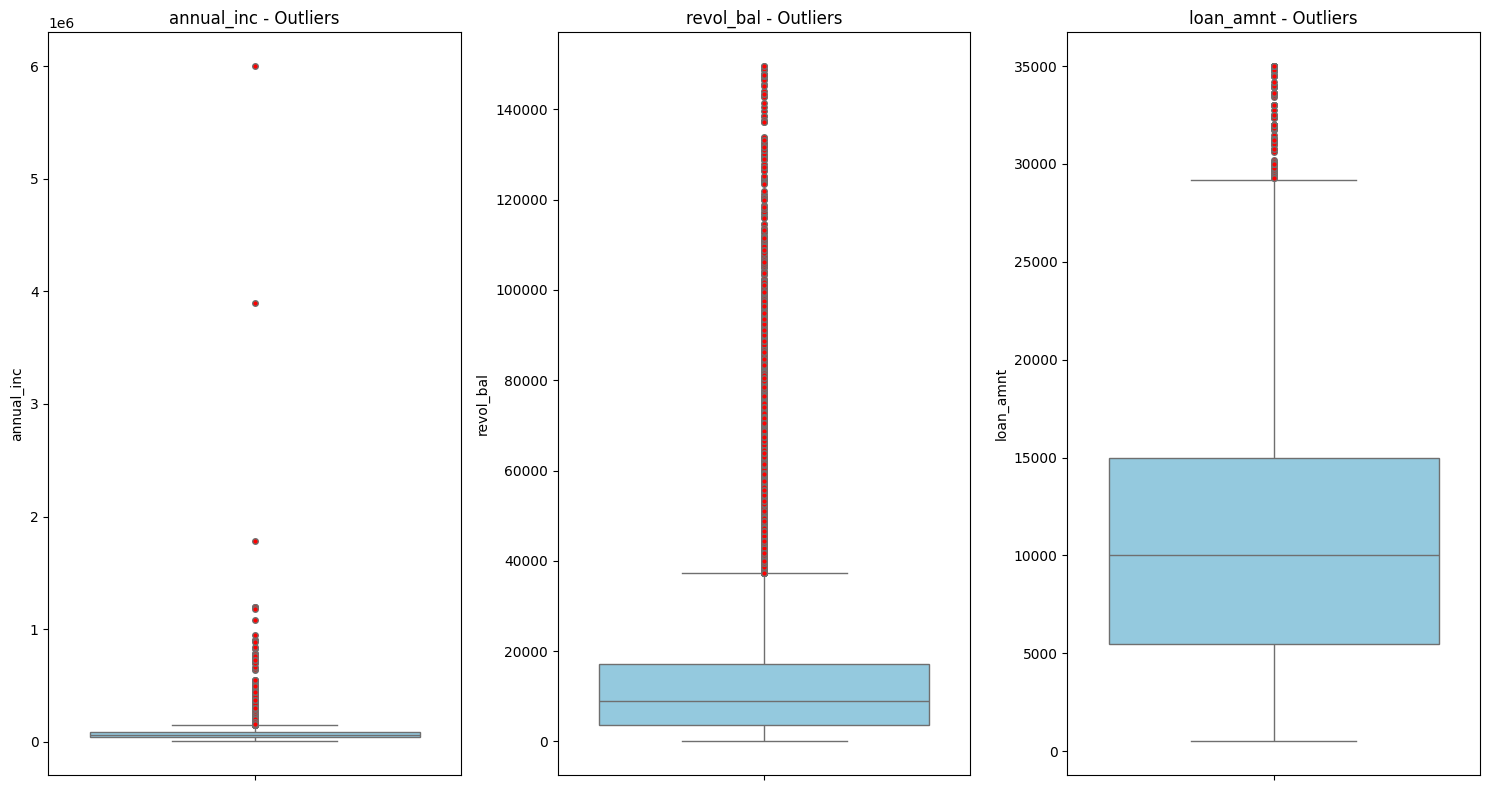

In [41]:
cols = [
    "annual_inc",
    "revol_bal",
    "loan_amnt",
 
]

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.boxplot(
        y=cd[col],
        ax=ax,
        color="skyblue",
        flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 4}
    )
    ax.set_title(f"{col} - Outliers")

plt.tight_layout()
plt.show()

In [42]:
print(cd["loan_status"].value_counts(normalize=True))

loan_status
0    0.855444
1    0.144556
Name: proportion, dtype: float64


In [43]:
cd.info()

<class 'pandas.DataFrame'>
Index: 25727 entries, 0 to 27002
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   loan_amnt               25727 non-null  int64  
 1   term_months             25727 non-null  int64  
 2   int_rate_pct            25727 non-null  float64
 3   installment             25727 non-null  float64
 4   sub_grade               25727 non-null  str    
 5   emp_length              25727 non-null  int64  
 6   home_ownership          25727 non-null  str    
 7   annual_inc              25727 non-null  float64
 8   verification_status     25727 non-null  str    
 9   loan_status             25727 non-null  int64  
 10  purpose                 25727 non-null  str    
 11  title                   25727 non-null  str    
 12  addr_state              25727 non-null  str    
 13  dti                     25727 non-null  float64
 14  delinq_2yrs             25727 non-null  int64  
 15  i

In [44]:
default_rate = cd["loan_status"].mean()
print(round(default_rate, 3))

0.145



----- term_months -----
             count   mean
term_months              
36           19273  0.108
60            6454  0.253


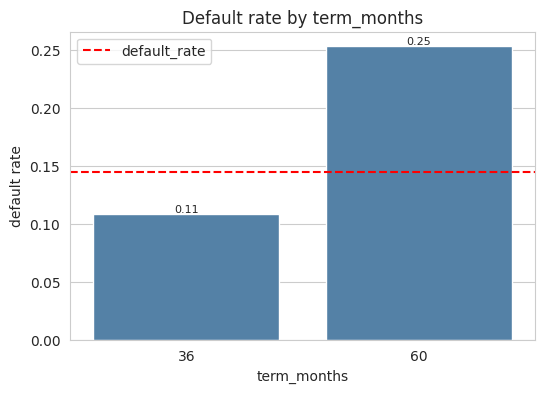


----- emp_length -----
            count   mean
emp_length              
0            3003  0.139
1            2112  0.147
2            2922  0.141
3            2776  0.139
4            2285  0.134
5            2224  0.144
6            1465  0.142
7            1146  0.151
8            1009  0.146
9             860  0.127
10           5925  0.157


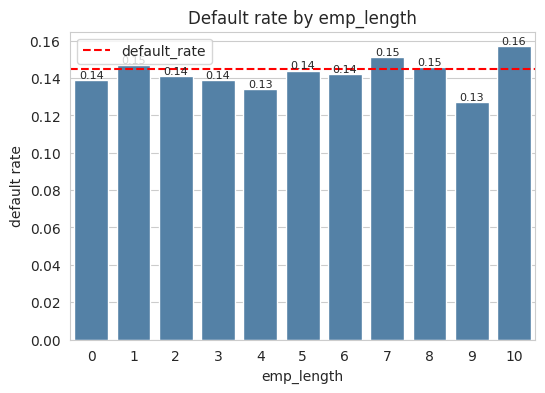


----- sub_grade -----
           count   mean
sub_grade              
A1           741  0.022
A2          1003  0.051
A3          1235  0.052
A4          1903  0.063
A5          1796  0.078
B1          1170  0.090
B2          1321  0.107
B3          1898  0.117
B4          1670  0.131
B5          1770  0.138
C1          1381  0.156
C2          1297  0.167
C3           967  0.183
C4           802  0.178
C5           744  0.180
D1           621  0.161
D2           821  0.212
D3           732  0.239
D4           621  0.242
D5           564  0.241
E1           496  0.270
E2           409  0.293
E3           331  0.230
E4           296  0.284
E5           255  0.298
F1           199  0.281
F2           162  0.290
F3           123  0.252
F4           103  0.388
F5            82  0.451
G1            74  0.338
G2            55  0.345
G3            27  0.407
G4            37  0.243
G5            21  0.381


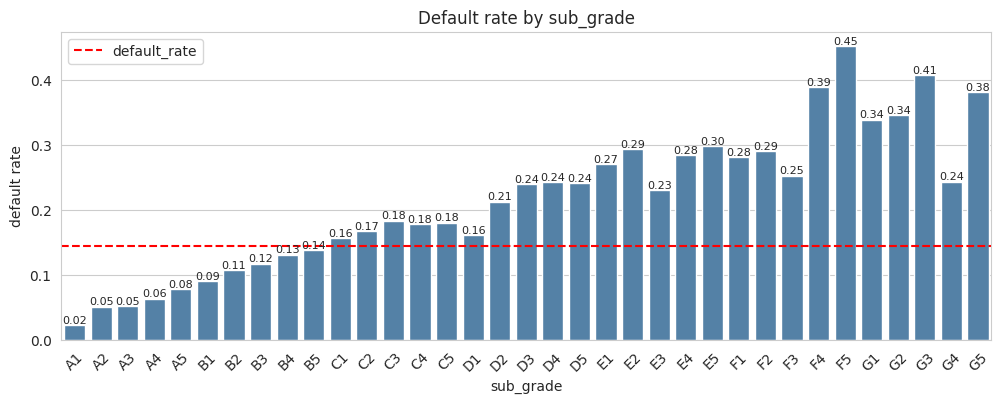

In [45]:
sns.set_style("whitegrid")

for col in ["term_months", "emp_length", "sub_grade"]:
    print(f"\n----- {col} -----")
    r = cd.groupby(col)["loan_status"].agg(["count", "mean"]).round(3)
    print(r)

    width = 12 if col == "sub_grade" else 6
    plt.figure(figsize=(width, 4))
    ax = sns.barplot(x=r.index.astype(str), y=r["mean"], color="steelblue")
    ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=8)
    plt.axhline(default_rate, color="red", linestyle="--", label="default_rate")
    plt.title(f"Default rate by {col}")
    plt.xlabel(col)
    plt.ylabel("default rate")
    plt.xticks(rotation=45 if col == "sub_grade" else 0)
    plt.legend()
    plt.show()

## ملاحظات: فئات ترتيبها طبيعي

**`term_months` (مدة القرض)**
- قرض 60 شهر نسبة تعثره حوالي **25%**، وقرض 36 شهر حوالي **11%**.
- يعني القرض الأطول **أخطر بأكتر من الضعف**.
- من أقوى الأعمدة في التأثير على التعثر.

**`emp_length` (سنين الخبرة)**
- نسبة التعثر ثابتة تقريباً بين **13% و 16%** في كل الفئات.
- **مش مؤثر** لوحده على التعثر.

**`sub_grade` (تقييم LC)**
- نسبة التعثر بتزيد تدريجياً مع الدرجة الأسوأ: من **2%** في A1 لحد **45%** في F5.
- **F5 أعلى فئة** (45%)، بس عدد عملائها قليل (82 عميل)، فالنسبة دي مش ثابتة بالكامل.
- فئات G كمان عملائها قليلين (أقل من 80 عميل)، فنتايجها متقلبة.
- العمود ده مرتبط جداً بـ `int_rate_pct` لأنه تقييم LC نفسه.


----- purpose -----
                    count   mean
purpose                         
small_business       1157  0.267
renewable_energy       66  0.182
house                 254  0.169
medical               470  0.166
other                2503  0.162
educational           196  0.153
debt_consolidation  12095  0.152
vacation              238  0.147
moving                367  0.139
home_improvement     1952  0.128
credit_card          3373  0.107
major_purchase       1437  0.105
wedding               621  0.101
car                   998  0.098


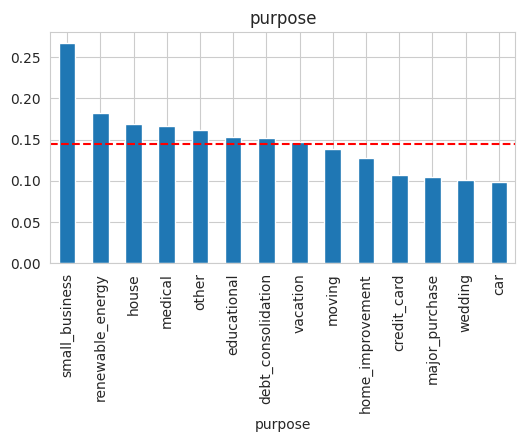


----- home_ownership -----
                count   mean
home_ownership              
RENT            12277  0.151
OWN              1912  0.149
MORTGAGE        11479  0.137
OTHER              59  0.136


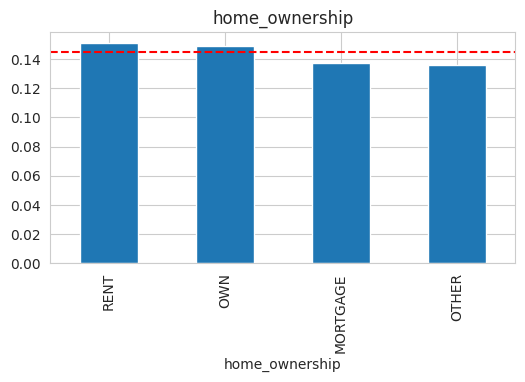


----- verification_status -----
                     count   mean
verification_status              
Verified              8273  0.169
Source Verified       6585  0.146
Not Verified         10869  0.125


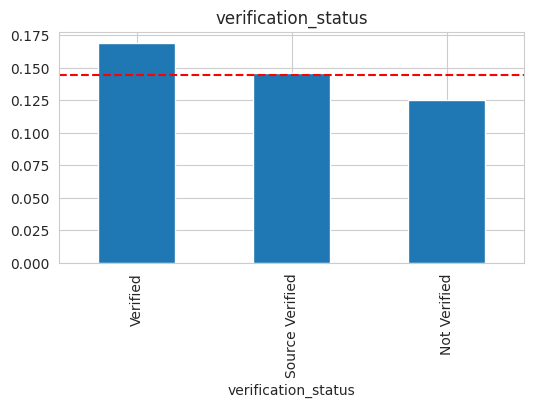

In [46]:
for col in ["purpose", "home_ownership", "verification_status"]:
    print(f"\n----- {col} -----")
    r = cd.groupby(col)["loan_status"].agg(["count", "mean"]).round(3).sort_values("mean", ascending=False)
    print(r)
    r["mean"].plot(kind="bar", figsize=(6, 3), title=col)
    plt.axhline(default_rate, color="red", linestyle="--")
    plt.show()

## ملاحظات: فئات ترتيبها أبجدي

**`home_ownership` (ملكية البيت)**
- نسبة التعثر متقاربة جداً بين كل الفئات (حوالي 14% - 15%).
- **مش مؤثر** على التعثر.

**`verification_status` (توثيق الدخل)**
- العميل **Not Verified** هو الأقل تعثراً (12.5%).
- العميل **Verified** هو الأكتر تعثراً (16.9%)، وده **عكس المتوقع**.

**`purpose` (الغرض من القرض)**
- `small_business` هو الأخطر بفرق كبير (27%).


----- int_rate_pct -----
                count   mean
int_rate_pct                
(5.419, 6.99]    2588  0.041
(6.99, 7.9]      2729  0.060
(7.9, 9.99]      2612  0.087
(9.99, 10.99]    2814  0.109
(10.99, 11.83]   2178  0.137
(11.83, 12.87]   2601  0.151
(12.87, 13.85]   2576  0.159
(13.85, 15.23]   2538  0.186
(15.23, 16.82]   2529  0.216
(16.82, 24.4]    2562  0.310


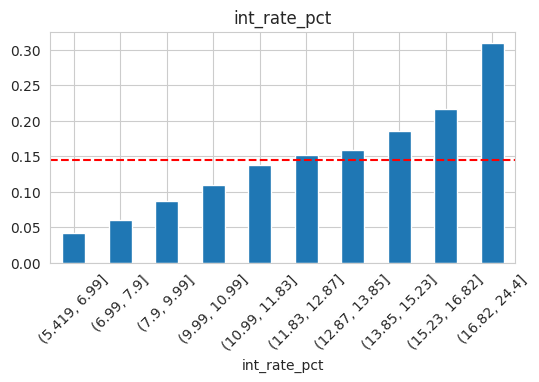


----- annual_inc -----
                       count   mean
annual_inc                         
(3999.999, 30000.0]     2859  0.182
(30000.0, 38000.0]      2351  0.177
(38000.0, 45000.0]      2849  0.163
(45000.0, 51000.0]      2248  0.149
(51000.0, 60000.0]      3474  0.159
(60000.0, 66000.0]      1676  0.137
(66000.0, 76500.0]      2558  0.127
(76500.0, 90000.0]      2610  0.128
(90000.0, 116488.0]     2529  0.108
(116488.0, 6000000.0]   2573  0.106


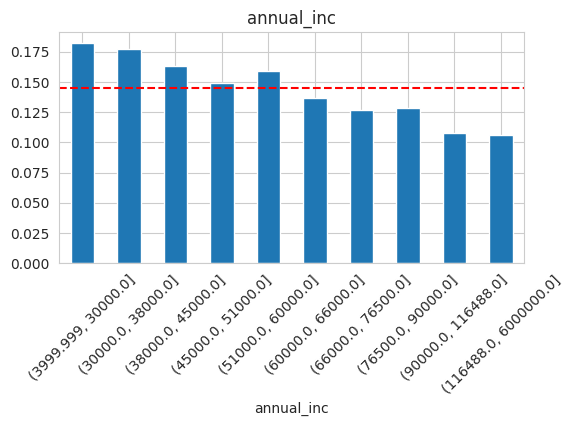


----- revol_util_pct -----
                count   mean
revol_util_pct              
(-0.001, 8.7]    2578  0.101
(8.7, 20.3]      2577  0.097
(20.3, 30.7]     2588  0.106
(30.7, 40.3]     2567  0.118
(40.3, 49.5]     2576  0.147
(49.5, 58.5]     2560  0.149
(58.5, 67.8]     2572  0.166
(67.8, 77.6]     2574  0.174
(77.6, 87.9]     2572  0.182
(87.9, 99.9]     2563  0.206


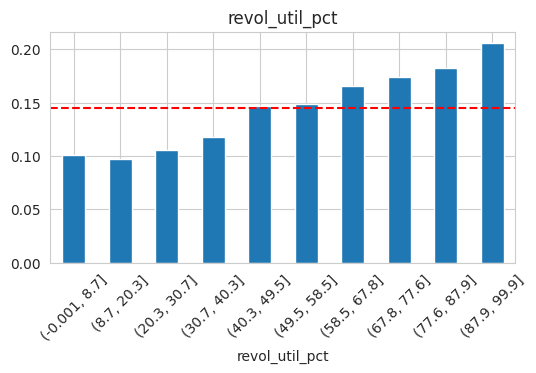


----- dti -----
                count   mean
dti                         
(-0.001, 4.16]   2579  0.131
(4.16, 7.04]     2575  0.117
(7.04, 9.32]     2565  0.132
(9.32, 11.42]    2581  0.127
(11.42, 13.42]   2578  0.140
(13.42, 15.34]   2569  0.149
(15.34, 17.44]   2564  0.152
(17.44, 19.71]   2580  0.162
(19.71, 22.29]   2564  0.170
(22.29, 29.99]   2572  0.165


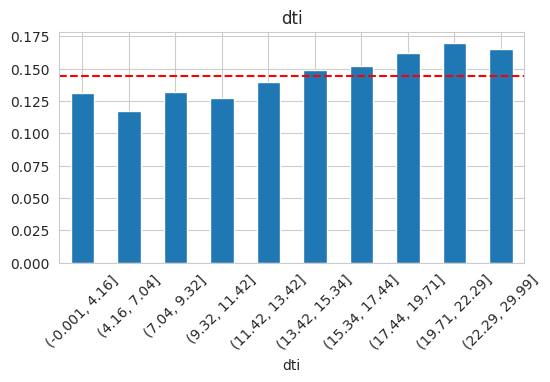


----- loan_amnt -----
                    count   mean
loan_amnt                       
(499.999, 3250.0]    2598  0.139
(3250.0, 5000.0]     3567  0.135
(5000.0, 6000.0]     1889  0.120
(6000.0, 8000.0]     3205  0.127
(8000.0, 10000.0]    3373  0.128
(10000.0, 11600.0]    810  0.116
(11600.0, 14000.0]   2803  0.137
(14000.0, 16660.0]   2336  0.155
(16660.0, 22000.0]   2630  0.176
(22000.0, 35000.0]   2516  0.203


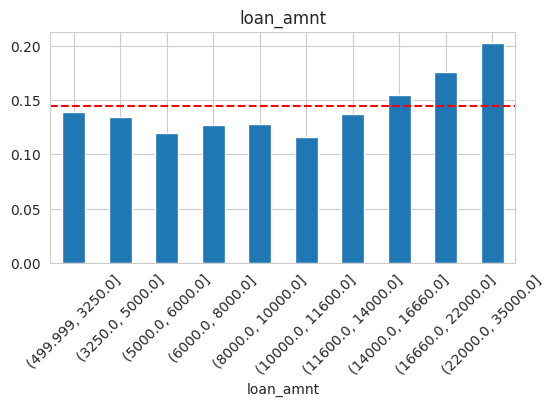

In [47]:
for col in ["int_rate_pct", "annual_inc", "revol_util_pct", "dti", "loan_amnt"]:
    print(f"\n----- {col} -----")
    bins = pd.qcut(cd[col], q=10, duplicates="drop")
    r = cd.groupby(bins, observed=True)["loan_status"].agg(["count", "mean"]).round(3)
    print(r)
    r["mean"].plot(kind="bar", figsize=(6, 3), title=col)
    plt.axhline(default_rate, color="red", linestyle="--")
    plt.xticks(rotation=45)
    plt.show()


----- installment -----
                               count   mean
installment                                
(16.078999999999997, 101.028]   2573  0.148
(101.028, 152.18]               2580  0.133
(152.18, 187.31]                2565  0.134
(187.31, 231.54]                2575  0.132
(231.54, 280.01]                2575  0.131
(280.01, 330.76]                2594  0.130
(330.76, 389.416]               2547  0.149
(389.416, 484.286]              2572  0.152
(484.286, 625.81]               2575  0.173
(625.81, 1302.69]               2571  0.164


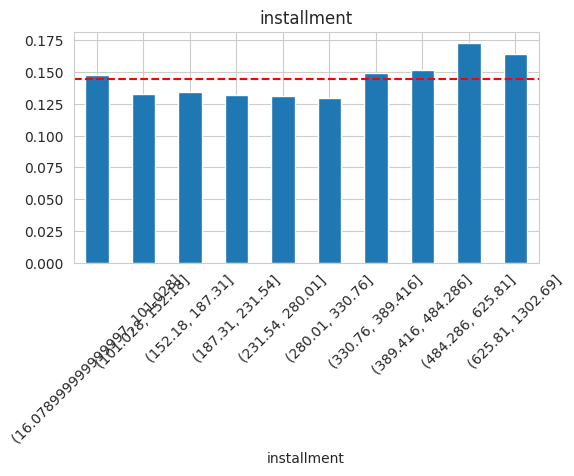


----- credit_history_years -----
                      count   mean
credit_history_years              
(2.999, 6.0]           3089  0.167
(6.0, 8.0]             2474  0.134
(8.0, 10.0]            3323  0.143
(10.0, 11.0]           2061  0.171
(11.0, 12.0]           1934  0.154
(12.0, 14.0]           3284  0.145
(14.0, 16.0]           2733  0.136
(16.0, 18.0]           1876  0.132
(18.0, 22.0]           2404  0.129
(22.0, 61.0]           2549  0.135


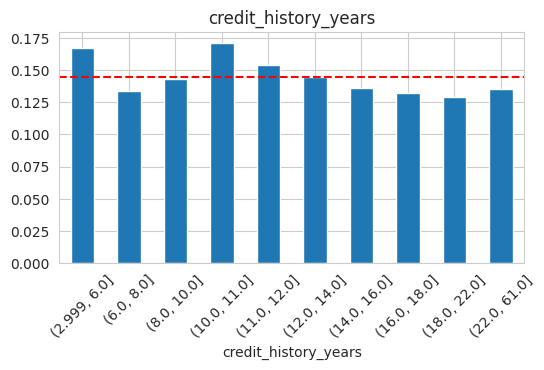


----- revol_bal -----
                     count   mean
revol_bal                        
(-0.001, 1158.0]      2575  0.141
(1158.0, 2848.2]      2571  0.130
(2848.2, 4659.0]      2573  0.135
(4659.0, 6657.0]      2573  0.140
(6657.0, 8934.0]      2572  0.148
(8934.0, 11572.6]     2572  0.137
(11572.6, 14904.2]    2573  0.159
(14904.2, 19782.0]    2573  0.149
(19782.0, 29219.8]    2572  0.158
(29219.8, 149588.0]   2573  0.149


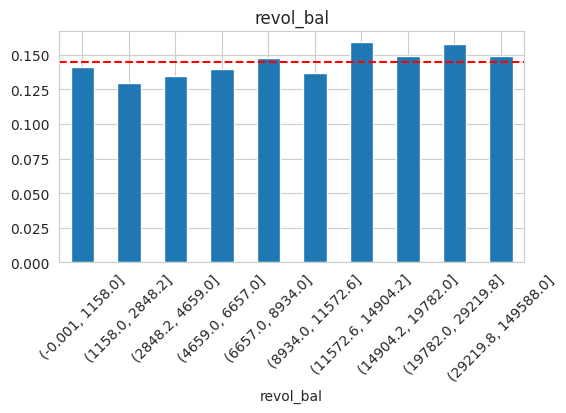


----- total_acc -----
              count   mean
total_acc                 
(1.999, 9.0]   3006  0.167
(9.0, 12.0]    2468  0.162
(12.0, 15.0]   2755  0.146
(15.0, 18.0]   2813  0.139
(18.0, 20.0]   1837  0.143
(20.0, 23.0]   2578  0.133
(23.0, 27.0]   2965  0.130
(27.0, 31.0]   2296  0.148
(31.0, 38.0]   2689  0.140
(38.0, 81.0]   2320  0.136


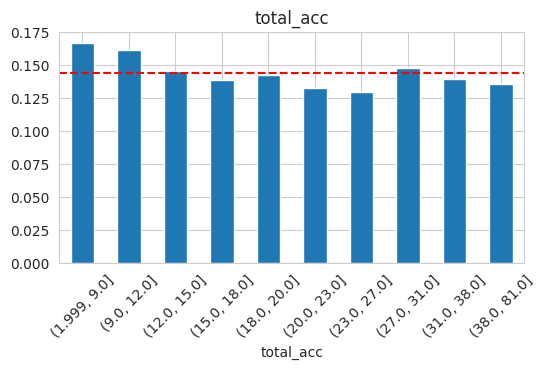


----- open_acc -----


              count   mean
open_acc                  
(1.999, 4.0]   2822  0.170
(4.0, 6.0]     4620  0.136
(6.0, 7.0]     2603  0.141
(7.0, 8.0]     2540  0.140
(8.0, 9.0]     2430  0.143
(9.0, 10.0]    2084  0.152
(10.0, 11.0]   1831  0.144
(11.0, 13.0]   2773  0.138
(13.0, 15.0]   1711  0.157
(15.0, 44.0]   2313  0.135


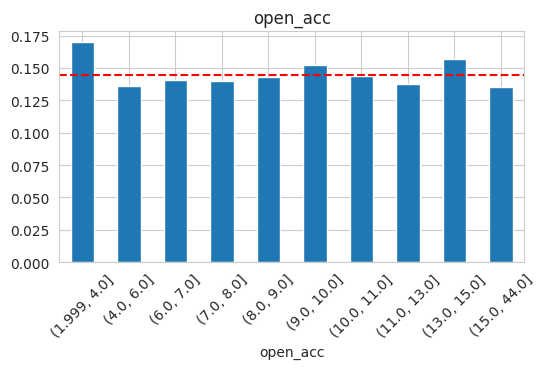

In [48]:
for col in ["installment", "credit_history_years", "revol_bal", "total_acc", "open_acc"]:
    print(f"\n----- {col} -----")
    bins = pd.qcut(cd[col], q=10, duplicates="drop")
    r = cd.groupby(bins, observed=True)["loan_status"].agg(["count", "mean"]).round(3)
    print(r)
    r["mean"].plot(kind="bar", figsize=(6, 3), title=col)
    plt.axhline(default_rate, color="red", linestyle="--")
    plt.xticks(rotation=45)
    plt.show()

## ملاحظات: أعمدة رقمية (مقسمة 10 شرايح متساوية العدد)

**مؤثرة:**

**`int_rate_pct` (سعر الفايدة)**
- نسبة التعثر بتزيد بشكل واضح مع الفايدة: من **4.1%** في أقل شريحة لحد **31%** في أعلى شريحة.
- **أقوى عمود** في التأثير على التعثر.
- مرتبط جداً بـ `sub_grade` لأن الفايدة بتتحدد على حسب تقييم LC.

**`revol_util_pct` (نسبة استخدام الائتمان)**
- بتزيد من **10.1%** لحد **20.6%** كل ما العميل يستخدم نسبة أكبر من الحد المتاح له.

**`annual_inc` (الدخل السنوي)**
- الدخل الأقل أكتر تعثراً: **18.2%** في أقل شريحة مقابل **10.6%** في أعلى شريحة.
- يعني كل ما الدخل زاد، التعثر بيقل.

**`loan_amnt` (مبلغ القرض)**
- المبالغ الكبيرة أخطر: **13.9%** في أصغر شريحة مقابل **20.3%** في أكبر شريحة.

**`dti` (نسبة الدين للدخل)**
- تأثير بسيط: من **13.1%** لحد **16.5%**.

**ضعيفة أو مش مؤثرة (النسبة قريبة من المتوسط 14.5% وبدون اتجاه واضح):**
- `installment` (القسط): من 13% لحد 17.3%، وفيه ارتفاع بسيط في أعلى الشرايح.
- `credit_history_years`:من 12.9% لحد 17.1%.
- `revol_bal`: من 13% لحد 15.9%.
- `total_acc` و`open_acc`: (مش مؤثره)النسبة قريبة من المتوسط في كل الشرايح.


----- has_delinq -----
            count   mean
has_delinq              
0           16871  0.139
1            8856  0.156


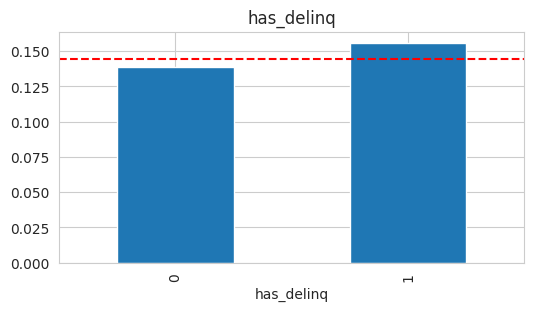


----- has_record -----
            count   mean
has_record              
0           24379  0.140
1            1348  0.231


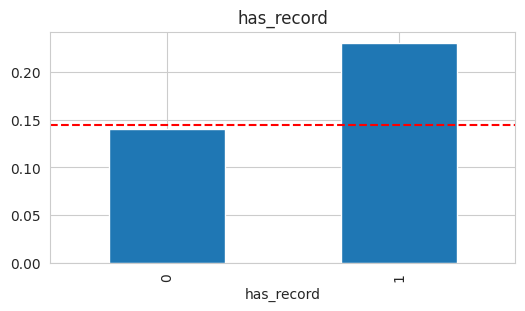


----- delinq_2yrs -----
             count   mean
delinq_2yrs              
0            22908  0.142
1             2170  0.157
2              444  0.189
3              132  0.159
4               41  0.268
5               19  0.105
6                6  0.167
7                3  0.333
8                2  0.500
9                1  0.000
11               1  0.000


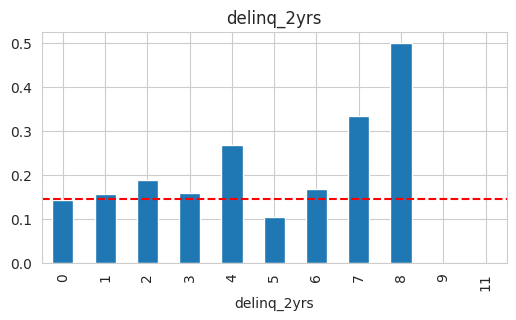


----- inq_last_6mths -----
                count   mean
inq_last_6mths              
0               12489  0.119
1                7142  0.158
2                3752  0.165
3                1966  0.211
4                 208  0.149
5                  94  0.223
6                  44  0.250
7                  22  0.364
8                  10  0.100


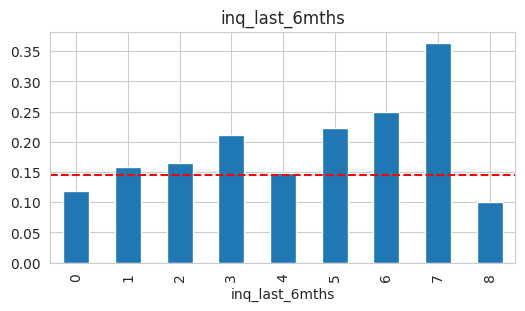


----- pub_rec -----
         count   mean
pub_rec              
0        24379  0.140
1         1308  0.232
2           32  0.250
3            6  0.000
4            2  0.000


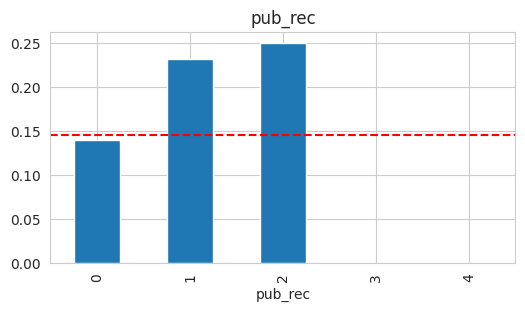


----- pub_rec_bankruptcies -----
                      count   mean
pub_rec_bankruptcies              
0.0                   24648  0.141
1.0                    1075  0.229
2.0                       4  0.500


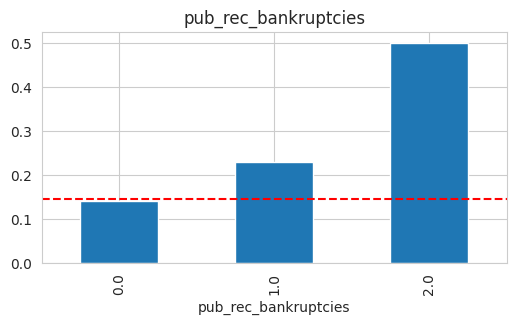

In [49]:
for col in ["has_delinq", "has_record", "delinq_2yrs", "inq_last_6mths", "pub_rec", "pub_rec_bankruptcies"]:
    print(f"\n----- {col} -----")
    r = cd.groupby(col)["loan_status"].agg(["count", "mean"]).round(3)
    print(r)
    r["mean"].plot(kind="bar", figsize=(6, 3), title=col)
    plt.axhline(default_rate, color="red", linestyle="--")
    plt.show()

                       count   mean
has_delinq has_record              
0          0           16105  0.135
           1             766  0.223
1          0            8274  0.150
           1             582  0.241


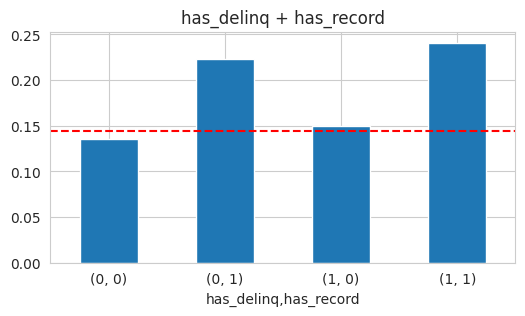

In [50]:
r = cd.groupby(["has_delinq", "has_record"])["loan_status"].agg(["count", "mean"]).round(3)
print(r)
r["mean"].plot(kind="bar", figsize=(6, 3), title="has_delinq + has_record")
plt.axhline(default_rate, color="red", linestyle="--")
plt.xticks(rotation=0)
plt.show()

In [51]:
print(cd["int_rate_pct"].corr(cd["loan_status"]))
print(cd["emp_length"].corr(cd["loan_status"]))

0.21660043180741712
0.014491065024768653


In [52]:
corr = cd.select_dtypes(include="number").corr()


print(corr["loan_status"].drop("loan_status").sort_values(ascending=False).round(3))

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.7].sort_values(ascending=False).round(2))

int_rate_pct              0.217
term_months               0.178
revol_util_pct            0.100
inq_last_6mths            0.076
loan_amnt                 0.064
has_record                0.058
pub_rec                   0.055
pub_rec_bankruptcies      0.051
dti                       0.042
installment               0.029
has_delinq                0.023
delinq_2yrs               0.021
mths_since_last_record    0.020
emp_length                0.014
revol_bal                 0.007
mths_since_last_delinq   -0.000
open_acc                 -0.009
credit_history_years     -0.021
total_acc                -0.025
annual_inc               -0.042
Name: loan_status, dtype: float64
pub_rec                 has_record              0.97
loan_amnt               installment             0.93
pub_rec_bankruptcies    has_record              0.89
pub_rec                 pub_rec_bankruptcies    0.84
mths_since_last_record  pub_rec_bankruptcies    0.83
dtype: float64


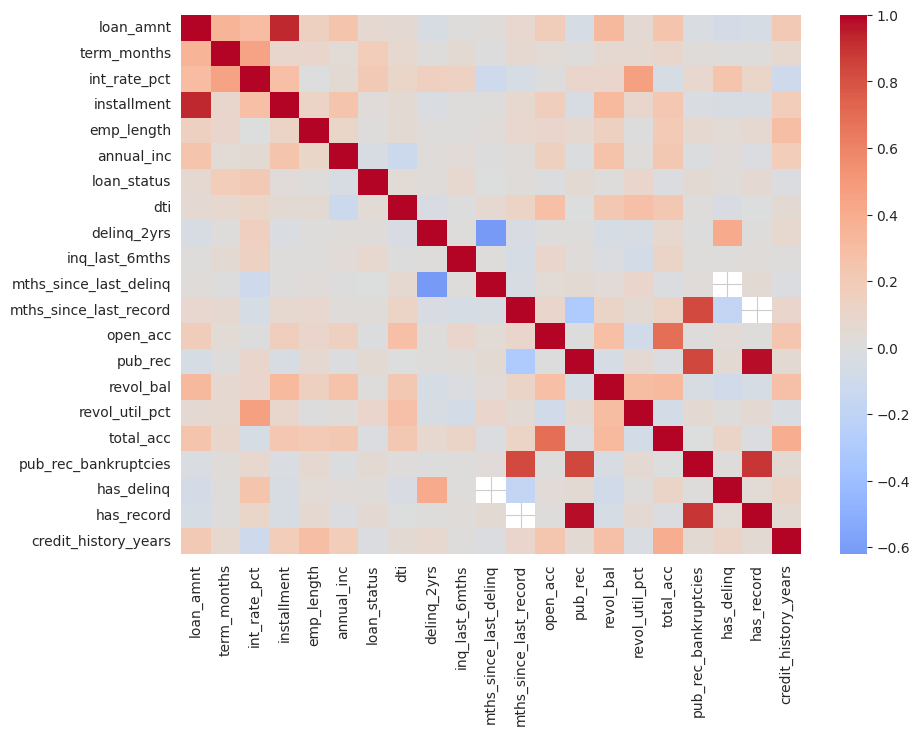

In [53]:
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()

annual_inc              37.06
revol_bal                3.20
installment              1.15
credit_history_years     1.10
loan_amnt                1.07
open_acc                 0.99
total_acc                0.82
dti                     -0.03
revol_util_pct          -0.04
dtype: float64


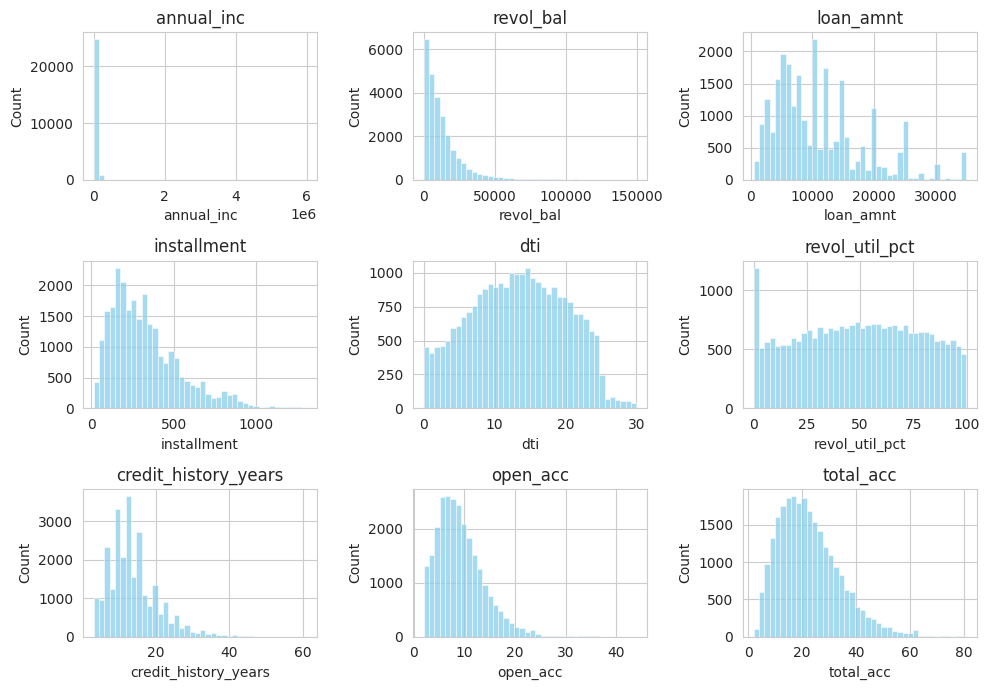

In [54]:
skew_cols = ["annual_inc", "revol_bal", "loan_amnt", "installment", "dti",
             "revol_util_pct", "credit_history_years", "open_acc", "total_acc"]

print(cd[skew_cols].skew().sort_values(ascending=False).round(2))

fig, axes = plt.subplots(3, 3, figsize=(10, 7))
for ax, col in zip(axes.flatten(), skew_cols):
    sns.histplot(cd[col], bins=40, ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Summary of Insights

**الداتا:** 25,727 قرض بعد التنضيف (من 27,003)، و27 عمود. نسبة التعثر **14.5%** (3,719 قرض).

## أعمدة مؤثرة على التعثر
- **`int_rate_pct` (الفايدة):** الأقوى. من 4.1% لحد 31% بين أقل وأعلى شريحة.
- **`term_months` (مدة القرض):** قرض 60 شهر نسبة تعثره 25% مقابل 11% لقرض 36 شهر.
- **`sub_grade` (تقييم LC):** بيزيد تدريجياً من 2% في A1 لحد 45% في F5 (عدد عملاء F5 قليل: 82).
- **`purpose` (الغرض):** `small_business` الأخطر (27%).
- **`annual_inc` (الدخل):** الدخل الأقل أكتر تعثراً (18.2% مقابل 10.6%).
- **`revol_util_pct`:** من 10.1% لحد 20.6%.
- **`loan_amnt`:** المبالغ الكبيرة أخطر (20.3% في أكبر شريحة).
- **السجل العام (`has_record`):** 23.1% مقابل 14%.
- **`inq_last_6mths`:** 11.9% (بدون استفسارات) لحد 21.1% (3 استفسارات).
- **`verification_status`:** العملاء الـ Verified أكتر تعثراً (16.9%) من Not Verified (12.5%)، وده عكس المتوقع. غالباً LC بتتأكد أكتر من العملاء الأخطر.

## أعمدة ضعيفة أو مش مؤثرة
- `emp_length` و`home_ownership` و`installment` و`credit_history_years` و`revol_bal` و`total_acc` و`open_acc`.


## ملاحظات على التنضيف
- شلنا أعمدة التعريف والنصوص الحرة وأعمدة التسريب (اللي بتتسجل بعد صرف القرض).
- شلنا 1,276 صف ناقصة، ونسبة التعثر ما اتغيرتش تقريباً (14.7% قبل، 14.5% بعد).
- القيم الشاذة (الدخل والمبلغ) حقيقية، فاحتفظنا بيها.

